# Assignment Instructions
## ✅ Rename the filename with your roll number. E.g. if your roll number is `MT22018` then rename the file `MT22018_a2.ipynb` before submitting.
## ✅ Write code only in the sections marked with `# YOUR CODE HERE`. No, you can NOT write code anywhere else.
## ✅ Download and extract the `data.zip` folder and `housing.csv` next to this file. If you extract it correctly, you will have a `data` folder next to this file.
## ❌ Do not modify any other function or class definitions; doing so may lead to the autograder failing to judge your submission, resulting in a zero.
## ❌ Deleting or adding new cells may lead to the `autograder` failing to judge your submission, resulting in a zero. Even if a cell is empty, do NOT delete it.
## ❌ Do NOT install / import any other libraries. You should be able to solve all the questions using only the libraries imported below.

In [1]:
import os
import json
import glob
import random
from typing import Dict, List, Any, Tuple, Optional
from abc import ABC, abstractmethod
import pandas as pd
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor
import scipy.stats as stats
import warnings
import numpy as np
from PIL import Image
import csv
import scipy
import sklearn
import seaborn as sns
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

PATH_TO_DATA_DIR = "./data"
PATH_TO_TRAIN_DIR = os.path.join(PATH_TO_DATA_DIR, "TRAIN")
PATH_TO_TEST_DIR = os.path.join(PATH_TO_DATA_DIR, "TEST")

PATH_TO_IMAGE_TRAIN_DIR = os.path.join(PATH_TO_TRAIN_DIR, "IMAGE")
PATH_TO_TEXT_TRAIN_DIR = os.path.join(PATH_TO_TRAIN_DIR, "TEXT")

PATH_TO_IMAGE_TEST_DIR = os.path.join(PATH_TO_TEST_DIR, "IMAGE")
PATH_TO_TEXT_TEST_DIR = os.path.join(PATH_TO_TEST_DIR, "TEXT")

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# `q1` Data Loading and Preprocessing

1. Populate the functions in all the Dataset classes in the following code cell only where the `### YOUR CODE HERE` marker is present.
2. Follow the instructions in the doc strings of the functions to implement the functions.
3. Grading [total: 2]
   1. `ImageDataset` class compiles and passes hidden tests with no errors: 1
   2. `TextDataset` class compiles and passes hidden tests with no errors: 1

In [2]:
class BaseDataset(ABC):
    """
    Shared interface for modality-specific datasets.

    Attributes
    - modality: string describing modality ("image" | "text"). Set by subclasses.
    """

    def __init__(self, data_dir: str):
        self.data_dir: str = data_dir
        self.modality: str = ""

    @abstractmethod
    def __len__(self) -> int:
        ...

    @abstractmethod
    def __getitem__(self, idx: int) -> Dict[str, Any]:
        ...


class ImageDataset(BaseDataset):
    """
    Load images organized under per-class folders.
    """

    def __init__(self, path_to_image_data_dir: str = PATH_TO_IMAGE_TRAIN_DIR):
        super().__init__(path_to_image_data_dir)
        self.modality = "image"
        self.records = []

        # YOUR CODE HERE

        for class_name in os.listdir(self.data_dir):
          class_path = os.path.join(self.data_dir, class_name)
          if os.path.isdir(class_path):
            for file_name in os.listdir(class_path):
              if file_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                full_path = os.path.join(class_path, file_name)
                self.records.append({
                  "path": full_path,
                  "class": class_name
                })

        random.shuffle(self.records)









    def __len__(self) -> int:
        return len(self.records)

    def __getitem__(self, idx: int) -> Dict[str, Any]:
        record = {
            "class": None,
        }
        # YOUR CODE HERE

        record_info = self.records[idx]
        img = Image.open(record_info["path"]).convert("RGB")
        record = {
            "image": img,
            "class": record_info["class"],
        }
        return record



class TextDataset(BaseDataset):
    """
    Load text data.
    """

    def __init__(self, path_to_text_data_dir: str = PATH_TO_TEXT_TRAIN_DIR):
        super().__init__(path_to_text_data_dir)
        self.modality = "text"
        self.records = []

        # YOUR CODE HERE

        jsonl_files = glob.glob(os.path.join(self.data_dir, "*.jsonl"))

        # Iterate through each file
        for file_path in jsonl_files:
            with open(file_path, "r", encoding="utf-8") as f:
              for line in f:
                if line.strip():
                    data = json.loads(line)

                    # text_parts = []

                    # for key, value in data.items():
                    #         if key not in ["label", "ID", "norm", "situation", "intention"] and isinstance(value, str):
                    #             # Lowercasing here helps normalize the corpus early
                    #             text_parts.append(value.lower())

                    # combined_text = " ".join(text_parts)

                    text_parts = []

                    handled_keys = {
                        "ID", "label", 
                        "situation", "intention", "norm", 
                        "action", "moral_action", "immoral_action", 
                        "consequence", "moral_consequence", "immoral_consequence"
                    }

                    if "situation" in data:
                        text_parts.append(data["situation"].lower())
                    if "intention" in data:
                        text_parts.append(data["intention"].lower())

                    if "norm" in data:
                        text_parts.extend([data["norm"].lower()] * 2)

                    # 3. The Core Behavior (Maximum weight: 4x)
                    action = data.get("moral_action", data.get("immoral_action", "")).lower()
                    if action:
                        text_parts.extend([action] * 4)

                    # 4. the outcome (high weight: 3x)
                    consequence = data.get("moral_consequence", data.get("immoral_consequence", "")).lower()
                    if consequence:
                        text_parts.extend([consequence] * 3)

                    for key, value in data.items():
                        if key not in handled_keys and isinstance(value, str):
                            text_parts.append(value.lower())

                    combined_text = " ".join(text_parts)

                    record = {
                        "text": combined_text,
                        "class": data.get("label")
                    }

                    self.records.append(record)


        random.shuffle(self.records)



    def __len__(self) -> int:
        return len(self.records)

    def __getitem__(self, idx: int) -> Dict[str, Any]:
        record = {
            "class": None,
        }
        # YOUR CODE HERE
        item = self.records[idx]
        record = {
            "text": item.get("text") or item.get("content"),
            "class": item.get("class"),
        }

        return record



    def get_corpus(self) -> List[str]:
        """
        [OPTIONAL]
        Return the full collection of text strings in the dataset.

        Requirement:
        - This function is optional and you may leave the code untouched if you do not want to use it.
        - Extract and return the raw text for each stored record.
        - Suggested use case: you can use this function to build tf-idf vectorizer later in the `get_text_features` function.
        """
        corpus = []
        # YOUR CODE HERE

        corpus = [item['text'] for item in self.records]

        return corpus


In [3]:
# DO NOT MODIFY
img_ds = ImageDataset()
print(f"[Q1] ImageDataset -> modality={img_ds.modality}, num_samples={len(img_ds)}")


[Q1] ImageDataset -> modality=image, num_samples=6168


In [4]:
# DO NOT MODIFY
text_ds = TextDataset()
print(f"[Q1] TextDataset -> modality={text_ds.modality}, num_samples={len(text_ds)}")

[Q1] TextDataset -> modality=text, num_samples=20000


# `q2` Samplers and DataLoader

1. Populate the functions in the all the `Sampler` classes in the following code cell only where the `### YOUR CODE HERE` marker is present.
2. Follow the instructions in the doc strings of the functions to implement the functions.
3. Grading [total: 2]
   1. `RandomSampler` class compiles and passes hidden tests with no errors: 1
   2. `WeightedRandomSampler` class compiles and passes hidden tests with no errors: 1

In [5]:
class BaseSampler(ABC):
    """Common interface for samplers"""

    @abstractmethod
    def sample_indices(self, dataset: BaseDataset, num_samples: Optional[int] = None) -> List[int]:
        ...

In [6]:
class RandomSampler(BaseSampler):
    """Uniform random sampler.

    Requirement:
    - Probability of each record being sampled is uniform.
    - Sampling is without replacement.
    - Works for any dataset modality.
    """

    def __init__(self, dataset: BaseDataset) -> None:
        """
        Initialize the uniform sampler.

        Requirement:
        - No precomputation is required; may store references if needed.
        """
        # YOUR CODE HERE

        self.dataset = dataset
        self.dataset_len = len(dataset)



    def sample_indices(self, dataset: BaseDataset, num_samples: Optional[int] = None) -> List[int]:
        """
        Draw indices uniformly at random without replacement.

        Requirement:
        - Every record has equal probability.
        - Respect `num_samples`; if None, select all records.
        - Return a list of unique indices.
        """
        # YOUR CODE HERE

        # This sample is Modal Agnostic: i.e. it never asks for which modality is this sampler for.
        #


        if num_samples is None:
            num_samples = len(dataset)
    
        num_samples = min(num_samples, len(dataset))
        
        indices = list(range(len(dataset)))
        return random.sample(indices, num_samples)


In [7]:
class WeightedRandomSampler(BaseSampler):
    """Weighted random sampler favoring least-similar classes.

    Requirement:
    - Derive class similarity internally (no external information):
      - Image: cosine similarity of grayscale histograms.
      - Text: cosine similarity of tokenized sentence vectors.
    - Convert similarity to weights that prefer less-similar classes (inverse similarity).
    - This mapping from class to weight should be stored in the `class_weights` attribute.
    - Sampling is
    """

    def __init__(self, dataset: BaseDataset) -> None:
        """
        Initialize and compute class weights from dataset-internal representations.

        Requirement:
        - Build a per-class representation per modality and compute pairwise cosine similarities.
        - Convert similarities into class-selection weights that emphasize dissimilar classes.
        - Do not use any external/precomputed similarity information.
        """
        self.class_weights = {}
        # YOUR CODE HERE

        class_indices = {}

        # Group indices by class
        for idx in range(len(dataset)):
            label = dataset[idx]['class']
            class_indices.setdefault(label, []).append(idx)

        # Compute class level mean (sample strategically to speed up)
        class_means = {}
        for label, indices in class_indices.items():
            features = []
            # for efficiency, sample up to 20 samples per class for computing class mean
            sample_indices = indices if len(indices) <= 20 else random.sample(indices, 20)
            for idx in sample_indices:
                sample = dataset[idx]
                if (dataset.modality == 'image'):
                  feature = get_image_features(sample)
                else:
                  feature = get_text_features(sample, corpus_texts=dataset.get_corpus())
                features.append(feature)
            class_means[label] = np.mean(features, axis=0)

        labels = list(class_means.keys())
        num_labels = len(labels)

        i = 0
        epsilon1 = 1e-9

        for l1 in labels:
            similarity = 0
            mean1 = class_means[l1]

            j = 0
            epsilon2 = 1e-9

            for l2 in labels:
                if (i==j): 
                    j += 1
                    continue
                mean2 = class_means[l2]
                similarity += np.dot(mean1, mean2) / (np.linalg.norm(mean1) * np.linalg.norm(mean2) + epsilon2)

                j += 1

            self.class_weights[l1] = 1 /(similarity + epsilon1)

            i += 1

    def sample_indices(self, dataset: BaseDataset, num_samples: Optional[int] = None) -> List[int]:
        """
        Sample record indices by first selecting classes via inverse-similarity weights.

        Requirement:
        - Respect `num_samples`; if None, select all available records.
        - Choose classes according to computed weights, then sample records without replacement.
        - Return a list of unique indices, length ≤ `num_samples`.
        """
        total_len = len(dataset)

        if num_samples is None:
            num_samples = total_len

        num_samples = min(num_samples, total_len)

        # Group dataset indices by class
        class_to_indices = {}
        for i in range(total_len):
            label = dataset[i]['class']
            class_to_indices.setdefault(label, []).append(i)

        labels = list(self.class_weights.keys())
        weights = np.array([self.class_weights[l] for l in labels])
        prob_weights = weights / weights.sum()

        selected_indices = []
        used_indices = set()

        while len(selected_indices) < num_samples:

            chosen_label = np.random.choice(labels, p=prob_weights)

            available = [
                idx for idx in class_to_indices[chosen_label]
                if idx not in used_indices
            ]

            if len(available) == 0:
                # no more unused samples in this class
                # remove class from sampling pool
                prob_weights[labels.index(chosen_label)] = 0
                if prob_weights.sum() == 0:
                    break
                prob_weights = prob_weights / prob_weights.sum()
                continue

            chosen_idx = random.choice(available)
            selected_indices.append(chosen_idx)
            used_indices.add(chosen_idx)

        return selected_indices



In [8]:
def get_image_features(sample: Dict[str, Any]) -> np.ndarray:
    """
    Get image features from a sample.
    """
    features = None
    # YOUR CODE HERE
    
    img = sample["image"].resize((32,32))

    arr = np.array(img, dtype=np.float32) / 255.0
    return arr.flatten()



def get_text_features(sample: Dict[str, Any], **kwargs) -> np.ndarray:
    """
    Get text features from a sample.

    Requirement:
    - Perform any type of feature engineering on the text as long as you do not import libraries that are not already imported.
    - You must populate the `features` variable with the features of the text.
    """
    features = None
    # YOUR CODE HERE

    # if not hasattr(get_text_features, "vocab_cache"):
    #     corpus_texts = kwargs.get('corpus_texts', [])

    #     word_counts = {}
    #     for sentence in corpus_texts:
    #         for word in sentence.lower().split():
    #             # Basic cleaning to ignore non-textual noise
    #             if word.isalpha():
    #                 word_counts[word] = word_counts.get(word, 0) + 1

    #     # top_words = sorted(word_counts, key=word_counts.get, reverse=True)[:1000]
    #     top_words = sorted(word_counts, key=word_counts.get, reverse=True)
    #     get_text_features.vocab_cache = sorted(top_words)
    #     get_text_features.index_map = {w: i for i, w in enumerate(get_text_features.vocab_cache)}


    # vocab = get_text_features.vocab_cache
    # word_to_index = get_text_features.index_map


    # text_content = sample.get("text", "").lower()
    # tokens = text_content.split()


    # features = np.zeros(len(vocab), dtype=np.float32)

    # for token in tokens:
    #     if token in word_to_index:
    #         features[word_to_index[token]] += 1

    # norm = np.linalg.norm(features)
    # if norm > 0:
    #     features /= norm

    # return features


    # config (tweakable)
    top_k = kwargs.get('top_k', 15000)  
    min_df = kwargs.get('min_df', 2)   
    # On first call build vocab, df and idf
    if not hasattr(get_text_features, "vocab_cache"):
        corpus_texts = kwargs.get('corpus_texts', []) or []
        N = len(corpus_texts)

        # count total term frequency and document frequency
        term_freq = {}
        doc_freq = {}

        for doc in corpus_texts:
            if not isinstance(doc, str):
                continue
            tokens = [w for w in doc.lower().split() if w.isalpha()]
            seen = set()
            for t in tokens:
                term_freq[t] = term_freq.get(t, 0) + 1
                if t not in seen:
                    doc_freq[t] = doc_freq.get(t, 0) + 1
                    seen.add(t)

        # apply min_df filter
        tokens_filtered = [t for t, df in doc_freq.items() if df >= min_df]

        # if nothing left, fall back to all tokens
        if len(tokens_filtered) == 0:
            tokens_filtered = list(term_freq.keys())

        # sort by term frequency (descending) and take top_k
        tokens_sorted = sorted(tokens_filtered, key=lambda t: term_freq.get(t, 0), reverse=True)
        top_tokens = tokens_sorted[:min(top_k, len(tokens_sorted))]

        # build index map
        index_map = {w: i for i, w in enumerate(top_tokens)}
        get_text_features.vocab_cache = top_tokens
        get_text_features.index_map = index_map

        # compute idf: idf = log((N + 1) / (df + 1)) + 1  (smoothing + shift)
        idf = np.ones(len(top_tokens), dtype=np.float32)
        for w, idx in index_map.items():
            df = doc_freq.get(w, 0)
            idf_val = np.log((N + 1.0) / (df + 1.0)) + 1.0
            idf[idx] = float(idf_val)
        get_text_features.idf_cache = idf

    # ready: compute tf for this sample and multiply by idf
    vocab = get_text_features.vocab_cache
    index_map = get_text_features.index_map
    idf = get_text_features.idf_cache
    V = len(vocab)

    text_content = sample.get("text", "") or ""
    tokens = [w for w in text_content.lower().split() if w.isalpha()]

    # build tf vector (counts)
    tf = np.zeros(V, dtype=np.float32)
    for t in tokens:
        if t in index_map:
            tf[index_map[t]] += 1.0

    # If empty (no tokens in vocab), return tiny zero-vector
    if V == 0 or np.all(tf == 0):
        return np.zeros(V, dtype=np.float32)

    # TF-IDF weighting: tf * idf
    tfidf = tf * idf

    # L2 normalize
    norm = np.linalg.norm(tfidf)
    if norm > 0:
        tfidf /= (norm + 1e-12)

    return tfidf

In [9]:
class DataLoader:
    """
    A modality and sampler agnostic data loader.
    """

    def __init__(self, modality: str, sampler: str, data_fraction: Optional[float] = None, is_train: bool = True) -> None:
        if is_train:
            path_to_image_dir = PATH_TO_IMAGE_TRAIN_DIR
            path_to_text_dir = PATH_TO_TEXT_TRAIN_DIR
        else:
            path_to_image_dir = PATH_TO_IMAGE_TEST_DIR
            path_to_text_dir = PATH_TO_TEXT_TEST_DIR

        self.modality = modality
        self.sampler_name = sampler
        self.data_fraction = data_fraction

        modality2dataset = {
            "image": ImageDataset(path_to_image_dir),
            "text": TextDataset(path_to_text_dir),
        }
        sampler_name2sampler_class = {
            "random": RandomSampler,
            "weighted_random": WeightedRandomSampler,
        }
        self.dataset = modality2dataset[self.modality]
        self.sampler = sampler_name2sampler_class[self.sampler_name](self.dataset)

    def get_features_and_labels(self) -> Tuple[List[np.ndarray], List[str]]:
        if self.data_fraction is None:
            self.data_fraction = len(self.dataset)
        num_samples = int(self.data_fraction * len(self.dataset))
        indices = self.sampler.sample_indices(self.dataset, num_samples)
        X: List[np.ndarray] = []
        y: List[Any] = []
        for idx in indices:
            sample = self.dataset[idx]
            if getattr(self.dataset, 'modality', '') == 'image':
                feat = get_image_features(sample)
                label = sample["class"]
            else:
                feat = get_text_features(sample, corpus_texts=self.dataset.get_corpus())
                label = sample.get("class")
            X.append(feat)
            y.append(label)
        return X, y

In [10]:
# DO NOT MODIFY

# === RANDOM SAMPLER TEST ===
for modality in ["image", "text"]:
    data_loader = DataLoader(modality=modality, sampler="random", data_fraction=0.05)
    X, y = data_loader.get_features_and_labels()
    shape = X[0].shape if len(X) > 0 else None
    print(f"[Q2] DataLoader({modality}, random) -> n={len(X)}, feat_shape={shape}, labels={set(y)}")

[Q2] DataLoader(image, random) -> n=308, feat_shape=(3072,), labels={'ned_flanders', 'marge_simpson', 'homer_simpson', 'bart_simpson', 'lisa_simpson', 'charles_montgomery_burns', 'milhouse_van_houten', 'principal_skinner', 'moe_szyslak', 'krusty_the_clown'}
[Q2] DataLoader(text, random) -> n=1000, feat_shape=(12247,), labels={'1', '0'}


In [11]:
# DO NOT MODIFY

# === WEIGHTED RANDOM SAMPLER TEST ===
for modality in ["image", "text"]:
    data_loader = DataLoader(modality=modality, sampler="weighted_random", data_fraction=0.05)
    X, y = data_loader.get_features_and_labels()
    shape = X[0].shape if len(X) > 0 else None
    print(f"[Q2] DataLoader({modality}, weighted_random) -> n={len(X)}, feat_shape={shape}, labels={set(y)}")

[Q2] DataLoader(image, weighted_random) -> n=308, feat_shape=(3072,), labels={'ned_flanders', 'marge_simpson', 'homer_simpson', 'lisa_simpson', 'charles_montgomery_burns', 'milhouse_van_houten', 'principal_skinner', 'moe_szyslak', 'bart_simpson', 'krusty_the_clown'}
[Q2] DataLoader(text, weighted_random) -> n=1000, feat_shape=(12247,), labels={'1', '0'}


# `q3` Model Trainer

1. Populate the `get_image_classifier`and `get_text_classifier` functions in the following code cells only where the `### YOUR CODE HERE` marker is present.
2. Follow the instructions in the doc strings of the functions to implement the functions.
3. Performance based Grading [total: 6]
   1. Per modality grading breakdown is given in the markdown cells below.

In [12]:
############################
# Q3: Model Trainer
############################

class ModelTrainer:
    def __init__(self, modality: str, sampler: str, data_fraction: Optional[float] = None):
        self.modality = modality
        self.sampler = sampler
        self.data_fraction = data_fraction

        self.train_dataloader = DataLoader(modality=modality, sampler=sampler, data_fraction=data_fraction, is_train=True)
        self.test_dataloader = DataLoader(modality=modality, sampler=sampler, data_fraction=None, is_train=False)

        self.train_features, self.train_labels = self.train_dataloader.get_features_and_labels()
        self.test_features, self.test_labels = self.test_dataloader.get_features_and_labels()

        # label encoding using LabelEncoder
        self.label_encoder = sklearn.preprocessing.LabelEncoder()
        self.train_labels = self.label_encoder.fit_transform(self.train_labels)
        self.test_labels = self.label_encoder.transform(self.test_labels)

        self.train_features = np.array(self.train_features)
        self.test_features = np.array(self.test_features)
        self.train_labels = np.array(self.train_labels)
        self.test_labels = np.array(self.test_labels)

    def train_classifier(self, classifier_object):
        self.classifier = classifier_object
        self.classifier.fit(self.train_features, self.train_labels)

    def evaluate_classifier(self):
        test_predictions = self.classifier.predict(self.test_features)
        self.confusion_matrix_ = sklearn.metrics.confusion_matrix(self.test_labels, test_predictions)
        accuracy = sklearn.metrics.accuracy_score(self.test_labels, test_predictions)
        self.plot_confusion_matrix()
        print(f'Accuracy for modality: {self.modality}, sampler: {self.sampler}, data fraction: {self.data_fraction} is {accuracy}')
        return accuracy

    def plot_confusion_matrix(self):
        label_names = self.label_encoder.inverse_transform(range(len(self.label_encoder.classes_)))
        plt.rcParams["figure.figsize"] = (7, 7)
        sns.heatmap(self.confusion_matrix_, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=label_names, yticklabels=label_names)
        plt.title(f'Confusion Matrix for modality: {self.modality}, sampler: {self.sampler}, data fraction: {self.data_fraction}')
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.tight_layout()
        plt.savefig(f'confusion_matrix_{self.modality}_{self.sampler}_{self.data_fraction}.png')

    def save_confusion_matrix(self):
        # save as numpy matrix
        np.save(f'confusion_matrix_{self.modality}_{self.sampler}_{self.data_fraction}.npy', self.confusion_matrix_)

## Image Classifier [3]
| Data Fraction | Sampler  | Classification Accuracy → Score                   |
| ------------- | -------- | ------------------------------------------------- |
| **10%**       | Random   | `>0.75` → 0.5, `0.75–0.5` → 0.3, `0.5–0.3` → 0.1, `<0.3` → 0 |
|               | Weighted | `>0.75` → 0.5, `0.75–0.5` → 0.3, `0.5–0.3` → 0.1, `<0.3` → 0 |
| **100%**      | Random   | `>0.9` → 1, `0.9–0.6` → 0.5, `0.6–0.4` → 0.25, `<0.4` → 0 |
|               | Weighted | `>0.9` → 1, `0.9–0.7` → 0.5, `0.7–0.5` → 0.25, `<0.5` → 0 |

In [13]:
from sklearn.svm import LinearSVC


def get_image_classifier():
    model = None
    # YOUR CODE HERE

    from sklearn.ensemble import RandomForestClassifier

    # # Original
    model = sklearn.ensemble.RandomForestClassifier(n_estimators=500, max_depth=None, class_weight='balanced', max_features='sqrt', min_samples_split=5, min_samples_leaf=3, random_state=42, bootstrap=True, n_jobs=-1)
    # model = sklearn.ensemble.RandomForestClassifier(class_weight='balanced_subsample', max_features='sqrt', min_samples_leaf=2, oob_score=True, n_estimators=500, max_depth=None, random_state=42)

    # model = sklearn.ensemble.RandomForestClassifier(
    #     n_estimators=500,              # more trees = better stability
    #     max_depth=None,                # let trees grow fully
    #     min_samples_split=5,           # prevent overfitting
    #     min_samples_leaf=3,            # smoother leaves
    #     max_features='sqrt',           # use 30% features instead of sqrt
    #     class_weight="balanced",
    #     bootstrap=True,
    #     random_state=42,
    #     n_jobs=-1
    # )



    # from sklearn.model_selection import GridSearchCV
    # base_model = RandomForestClassifier(random_state=42)

    # param_grid = {
    #     "n_estimators": [100, 200],
    #     "max_depth": [None, 20, 30],
    #     "min_samples_leaf": [1, 2],
    #     "max_features": ["sqrt", None],
    #     "class_weight": [None, "balanced"]
    # }

    # model = GridSearchCV(
    #     estimator=base_model,
    #     param_grid=param_grid,
    #     cv=3,
    #     n_jobs=-1,
    #     verbose=1
    # )

    return model


Training Image Classifier for data fraction: 0.1, sampler: random
Accuracy for modality: image, sampler: random, data fraction: 0.1 is 0.44125
Training Image Classifier for data fraction: 0.1, sampler: weighted_random
Accuracy for modality: image, sampler: weighted_random, data fraction: 0.1 is 0.43
Training Image Classifier for data fraction: 1, sampler: random
Accuracy for modality: image, sampler: random, data fraction: 1 is 0.640625
Training Image Classifier for data fraction: 1, sampler: weighted_random
Accuracy for modality: image, sampler: weighted_random, data fraction: 1 is 0.636875


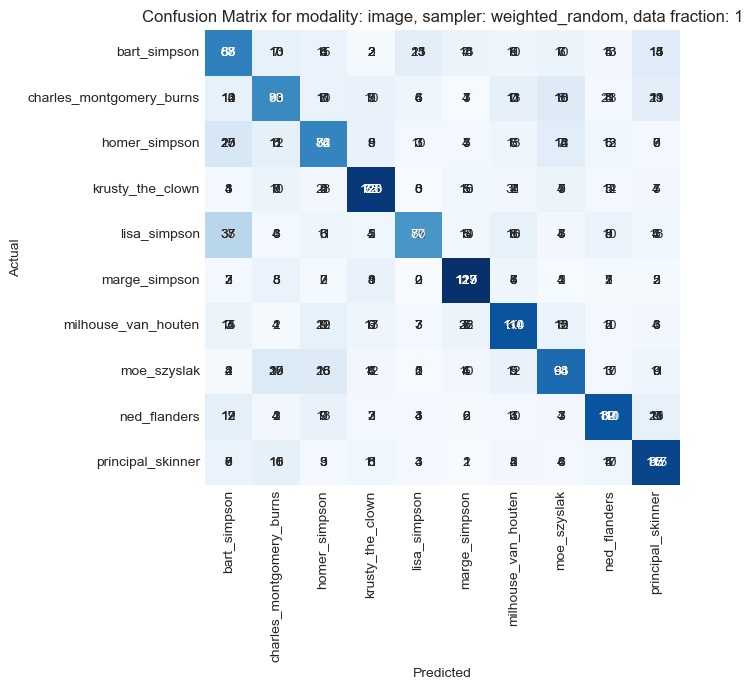

In [14]:
# Image Classifier
for data_fraction in [0.1, 1]:
    for sampler in ["random", "weighted_random"]:
        print(f"Training Image Classifier for data fraction: {data_fraction}, sampler: {sampler}")
        image_classifier = get_image_classifier()
        model_trainer = ModelTrainer(modality="image", sampler=sampler, data_fraction=data_fraction)
        model_trainer.train_classifier(image_classifier)
        model_trainer.evaluate_classifier()
        model_trainer.save_confusion_matrix()


## Text Classifier [3]
| Data Fraction | Sampler  | Classification Accuracy → Score                   |
| ------------- | -------- | ------------------------------------------------- |
| **10%**       | Random   | `>0.75` → 0.5, `0.75–0.65` → 0.3, `0.65–0.5` → 0.1, `<0.5` → 0 |
|               | Weighted | `>0.75` → 0.5, `0.75–0.65` → 0.3, `0.65–0.5` → 0.1, `<0.5` → 0 |
| **100%**      | Random   | `>0.8` → 1, `0.8–0.7` → 0.5, `0.7–0.5` → 0.25, `<0.5` → 0 |
|               | Weighted | `>0.9` → 1, `0.9–0.7` → 0.5, `0.7–0.5` → 0.25, `<0.5` → 0 |


In [16]:
def get_text_classifier():
    model = None
    # YOUR CODE HERE

    from sklearn.linear_model import LogisticRegression




    model = LogisticRegression(max_iter=3000, C=10.0)

    # from sklearn.model_selection import GridSearchCV
    # base_model = LogisticRegression(max_iter=3000)

    # param_grid = {
    #     "C": [0.1, 1, 5, 10, 50],
    #     "solver": ["lbfgs", "liblinear"],
    #     "class_weight": [None, "balanced"]
    # }

    # model = GridSearchCV(
    #     estimator=base_model,
    #     param_grid=param_grid,
    #     cv=3,
    #     n_jobs=-1,
    #     verbose=1
    # )


    # # 100% --> 0.79
    # model = MultinomialNB(alpha=0.5)  


    # # 100% --> 0.78
    # model = LinearSVC(
    #     C=1.0,
    #     class_weight='balanced',
    #     max_iter=2000,
    #     dual=False,
    #     random_state=42
    # )


    return model


Training Text Classifier for data fraction: 0.1, sampler: random
Accuracy for modality: text, sampler: random, data fraction: 0.1 is 0.7245
Training Text Classifier for data fraction: 0.1, sampler: weighted_random
Accuracy for modality: text, sampler: weighted_random, data fraction: 0.1 is 0.733
Training Text Classifier for data fraction: 1, sampler: random
Accuracy for modality: text, sampler: random, data fraction: 1 is 0.824
Training Text Classifier for data fraction: 1, sampler: weighted_random
Accuracy for modality: text, sampler: weighted_random, data fraction: 1 is 0.8265


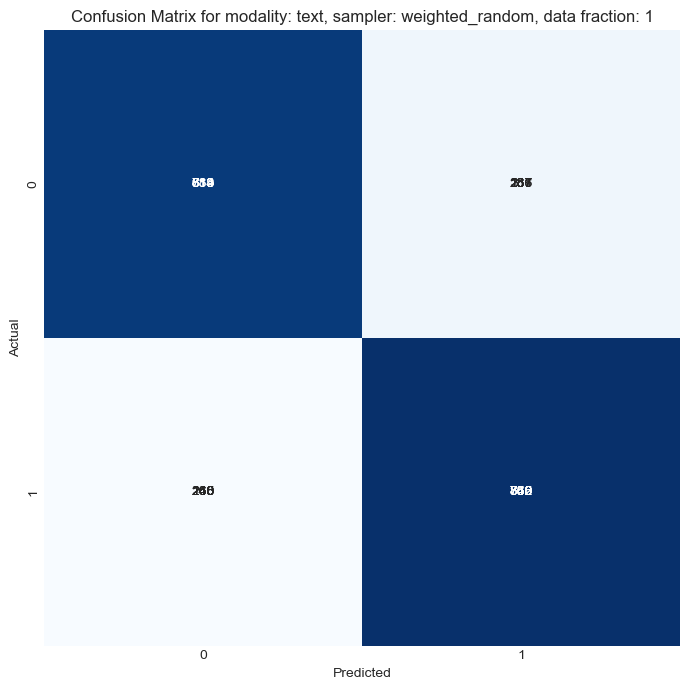

In [17]:
# Text Classifier
for data_fraction in [0.1, 1]:
    for sampler in ["random", "weighted_random"]:
        print(f"Training Text Classifier for data fraction: {data_fraction}, sampler: {sampler}")
        text_classifier = get_text_classifier()
        model_trainer = ModelTrainer(modality="text", sampler=sampler, data_fraction=data_fraction)
        model_trainer.train_classifier(text_classifier)
        model_trainer.evaluate_classifier()
        model_trainer.plot_confusion_matrix()
        model_trainer.save_confusion_matrix()


# Q4 Implement Linear Regression from Scratch (Using NumPy) (2.0 Points)

1) Normal Equation
2) Gradient Descent

## Understanding the Math Behind Linear Regression

**Linear Regression Model:**
$$\hat{y} = X \cdot \beta$$

**Cost Function (Mean Squared Error):**
$$J(\beta) = \frac{1}{2m} \sum_{i=1}^{m} (\hat{y}_i - y_i)^2$$

**Normal Equation (Closed-form solution):**
$$\beta = (X^T X)^{-1} X^T y$$

**Gradient Descent Update Rule:**
$$\beta := \beta - \alpha \cdot \frac{1}{m} X^T (X\beta - y)$$

In [18]:
class LinearRegressionScratch:
    """
    Linear Regression implementation from scratch using NumPy.

    Supports two methods:
    1. Normal Equation (closed-form solution)
    2. Gradient Descent (iterative optimization)
    """

    def __init__(self, method='normal', learning_rate=0.01, n_iterations=1000):
        """
        Initialize the Linear Regression model.

        Parameters:
        -----------
        method : str
            'normal' for Normal Equation, 'gradient' for Gradient Descent
        learning_rate : float
            Learning rate for gradient descent (alpha)
        n_iterations : int
            Number of iterations for gradient descent
        """
        # YOUR CODE HERE
        self.method = method
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.theta = None
        self.cost_history = []

        


    def _add_bias_term(self, X):
        """
        Add a column of ones for the bias term.

        Parameters:
        -----------
        X : numpy array
            Feature matrix of shape (m, n)

        Returns:
        --------
        X_b : numpy array
            Feature matrix with bias column, shape (m, n+1)
        """
        # YOUR CODE HERE

        ones = np.ones((X.shape[0], 1))
        return np.concatenate([ones, X], axis=1)


    def _compute_cost(self, X, y, theta):
        """
        Compute the Mean Squared Error cost function.

        Parameters:
        -----------
        X : numpy array
            Feature matrix with bias term (m, n+1)
        y : numpy array
            Target values (m,)
        theta : numpy array
            Model parameters (n+1,)

        Returns:
        --------
        cost : float
            Mean Squared Error
        """
        # YOUR CODE HERE

        m = len(y)
        predictions = X.dot(theta)
        cost = (1 / (2*m)) * np.sum(np.square(predictions - y))
        return cost


    def _compute_gradient(self, X, y, theta):
        """
        Compute the gradient of the cost function.

        Parameters:
        -----------
        X : numpy array
            Feature matrix with bias term (m, n+1)
        y : numpy array
            Target values (m,)
        theta : numpy array
            Model parameters (n+1,)

        Returns:
        --------
        gradient : numpy array
            Gradient vector (n+1,)
        """
        # YOUR CODE HERE

        m = len(y)
        predictions = X.dot(theta)
        gradient = (1 / m) * X.T.dot(predictions - y)
        return gradient


    def fit_normal_equation(self, X, y):
        """
        Fit the model using the Normal Equation (closed-form solution).

        Formula: θ = (X^T X)^(-1) X^T y

        Parameters:
        -----------
        X : numpy array
            Feature matrix (m, n)
        y : numpy array
            Target values (m,)
        """
        # YOUR CODE HERE

        X_b = self._add_bias_term(X)
        self.theta = np.linalg.pinv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)


    def fit_gradient_descent(self, X, y):
        """
        Fit the model using Gradient Descent optimization.

        Parameters:
        -----------
        X : numpy array
            Feature matrix (m, n)
        y : numpy array
            Target values (m,)
        """
        # YOUR CODE HERE

        X_b = self._add_bias_term(X)
        m, n = X_b.shape
        self.theta = np.zeros(n)

        for _ in range(self.n_iterations):
            gradient = self._compute_gradient(X_b, y, self.theta)
            self.theta -= self.learning_rate * gradient
            self.cost_history.append(self._compute_cost(X_b, y, self.theta))


    def fit(self, X, y):
        """
        Fit the model using the specified method.

        Parameters:
        -----------
        X : numpy array
            Feature matrix (m, n)
        y : numpy array
            Target values (m,)
        """
        # YOUR CODE HERE
        if self.method == 'normal':
            self.fit_normal_equation(X, y)
        else:
            self.fit_gradient_descent(X, y)
        self.bias = self.theta[0] 
        self.weights = self.theta[1:]


    def predict(self, X):
        """
        Make predictions using the fitted model.

        Parameters:
        -----------
        X : numpy array
            Feature matrix (m, n)

        Returns:
        --------
        predictions : numpy array
            Predicted values (m,)
        """
        # YOUR CODE HERE
        
        X_b = self._add_bias_term(X)
        return X_b.dot(self.theta)

    def score(self, X, y):
        """
        Calculate R² score (coefficient of determination).

        Parameters:
        -----------
        X : numpy array
            Feature matrix (m, n)
        y : numpy array
            True target values (m,)

        Returns:
        --------
        r2 : float
            R² score
        """
        # YOUR CODE HERE
        
        y_pred = self.predict(X)
        ssr = np.sum((y - y_pred) ** 2)
        sst = np.sum((y - np.mean(y)) ** 2)
        return 1 - (ssr / sst)


    @property
    def coef_(self):
        """Return the coefficients (weights)."""
        return self.weights

    @property
    def intercept_(self):
        """Return the intercept (bias)."""
        return self.bias

In [19]:
def run_complete_analysis(filepath, target_column='median_house_value', test_size=0.25, random_state=42):
    """
    Complete end-to-end linear regression analysis pipeline.
    
    Parameters:
    -----------
    filepath : str
        Path to the CSV file
    target_column : str
        Name of the target variable column
    test_size : float
        Proportion of data to use for testing (default: 0.25)
    random_state : int
        Random seed for reproducibility (default: 42)
    
    Returns:
    --------
    dict : Dictionary containing all models, data splits, and results
    """
    # 1. Load Data
    print("\n[1/5] Loading data...")
    df = pd.read_csv(filepath)
    print(f"✓ Loaded {df.shape[0]} rows and {df.shape[1]} columns")
    
    # 2. Handle Missing Values
    print("\n[2/5] Handling missing values...")
    df_cleaned = df.copy()
    numeric_cols = df_cleaned.select_dtypes(include=[np.number]).columns
    missing_count = 0
    for col in numeric_cols:
        null_count = df_cleaned[col].isnull().sum()
        if null_count > 0:
            median_val = df_cleaned[col].median()
            df_cleaned[col].fillna(median_val, inplace=True)
            missing_count += null_count
    print(f"✓ Filled {missing_count} missing values with median")
    
    # 3. Prepare Data
    print("\n[3/5] Preparing data for modeling...")
    numeric_cols = df_cleaned.select_dtypes(include=[np.number]).columns.tolist()
    numeric_cols.remove(target_column)
    
    X = df_cleaned[numeric_cols]
    y = df_cleaned[target_column]
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    print(f"✓ Train set: {X_train.shape[0]} samples")
    print(f"✓ Test set: {X_test.shape[0]} samples")
    print(f"✓ Features: {len(numeric_cols)}")
    
    # 4. Train Models
    print("\n[4/5] Training models...")
    
    # Normal Equation Method
    print("\n--- Normal Equation Method ---")
    model_normal = LinearRegressionScratch(method='normal')
    model_normal.fit(X_train_scaled, y_train.values)
    
    r2_train_normal = model_normal.score(X_train_scaled, y_train.values)
    r2_test_normal = model_normal.score(X_test_scaled, y_test.values)
    
    print(f"Intercept: {model_normal.intercept_:.4f}")
    print(f"Coefficients: {model_normal.coef_[:3]}... (showing first 3)")
    print(f"R² (Train): {r2_train_normal:.4f}")
    print(f"R² (Test): {r2_test_normal:.4f}")
    
    # Gradient Descent Method
    print("\n--- Gradient Descent Method ---")
    model_gd = LinearRegressionScratch(method='gradient', learning_rate=0.01, n_iterations=1000)
    model_gd.fit(X_train_scaled, y_train.values)
    
    r2_train_gd = model_gd.score(X_train_scaled, y_train.values)
    r2_test_gd = model_gd.score(X_test_scaled, y_test.values)
    
    print(f"Intercept: {model_gd.intercept_:.4f}")
    print(f"Coefficients: {model_gd.coef_[:3]}... (showing first 3)")
    print(f"R² (Train): {r2_train_gd:.4f}")
    print(f"R² (Test): {r2_test_gd:.4f}")
    
    # 5. Visualize Results
    print("\n[5/5] Generating visualizations...")
    if len(model_gd.cost_history) > 0:
        plt.figure(figsize=(10, 5))
        plt.plot(model_gd.cost_history, color='steelblue', linewidth=2)
        plt.xlabel('Iteration', fontsize=12)
        plt.ylabel('Cost (MSE)', fontsize=12)
        plt.title('Gradient Descent Convergence', fontsize=14, fontweight='bold')
        plt.grid(True, alpha=0.3)
        plt.show()
    
    print("\n" + "="*60)
    print("✓ ANALYSIS COMPLETE!")
    print("="*60)
    
    # Return all components for further analysis if needed
    return {
        'data': {
            'X_train': X_train,
            'X_test': X_test,
            'y_train': y_train,
            'y_test': y_test,
            'X_train_scaled': X_train_scaled,
            'X_test_scaled': X_test_scaled,
            'feature_names': numeric_cols
        },
        'models': {
            'normal_equation': model_normal,
            'gradient_descent': model_gd
        },
        'scaler': scaler,
        'results': {
            'normal_r2_train': r2_train_normal,
            'normal_r2_test': r2_test_normal,
            'gd_r2_train': r2_train_gd,
            'gd_r2_test': r2_test_gd
        }
    }

---